In [1]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, time, shutil
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]

from delta import configure_spark_with_delta_pip
from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

builder = (SparkSession.builder.appName("EP3-Benchmark").master("local[*]")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g"))
spark = configure_spark_with_delta_pip(builder).getOrCreate()
spark.sparkContext.setLogLevel("WARN")

def tamano_mb(path):
    return sum(os.path.getsize(os.path.join(r, f))
               for r, _, fs in os.walk(path) for f in fs
               if not f.endswith(".crc")) / 1024 / 1024

def escribir_y_medir(df, formato, codec, ruta):
    if os.path.exists(ruta): shutil.rmtree(ruta)
    t0 = time.time()
    w = df.write.mode("overwrite")
    if codec: w = w.option("compression", codec)
    if formato == "csv":
        w.option("header", "true").csv(ruta)
    elif formato == "parquet":
        w.parquet(ruta)
    else:
        w.format("delta").save(ruta)
    return time.time() - t0, tamano_mb(ruta)

In [3]:
df_bench = (spark.read.format("delta").load("outputs/silver_delta")
            .repartition(8).persist(StorageLevel.MEMORY_AND_DISK))
n = df_bench.count()
print(f"Dataset: {n:,} filas x {len(df_bench.columns)} columnas")

Dataset: 7,728,329 filas x 47 columnas


In [4]:
configs = [
    ("csv", None, "outputs/bench/csv"),
    ("parquet", "snappy", "outputs/bench/parquet_snappy"),
    ("parquet", "zstd", "outputs/bench/parquet_zstd"),
    ("parquet", "gzip", "outputs/bench/parquet_gzip"),
    ("delta", "zstd", "outputs/bench/delta_zstd"),
]
res = []
for fmt, codec, ruta in configs:
    label = f"{fmt}+{codec}" if codec else fmt
    t_w, mb = escribir_y_medir(df_bench, fmt, codec, ruta)
    res.append({"formato": label, "fmt": fmt, "ruta": ruta,
                "escritura_s": t_w, "tamano_mb": mb})
    print(f"{label:16s} escritura={t_w:6.1f}s  tamaño={mb:8.1f} MB")

mb_csv = res[0]["tamano_mb"]
for r in res:
    r["ratio_vs_csv"] = mb_csv / r["tamano_mb"]
    print(f"{r['formato']:16s} {r['ratio_vs_csv']:.1f}x más pequeño que CSV")

csv              escritura=  50.2s  tamaño=  2586.7 MB
parquet+snappy   escritura=  77.7s  tamaño=   602.0 MB
parquet+zstd     escritura=  71.8s  tamaño=   443.1 MB
parquet+gzip     escritura=  79.0s  tamaño=   448.3 MB
delta+zstd       escritura= 120.1s  tamaño=   443.1 MB
csv              1.0x más pequeño que CSV
parquet+snappy   4.3x más pequeño que CSV
parquet+zstd     5.8x más pequeño que CSV
parquet+gzip     5.8x más pequeño que CSV
delta+zstd       5.8x más pequeño que CSV


In [5]:
esquema = df_bench.schema
df_bench.unpersist()
spark.catalog.clearCache()

def leer(ruta, fmt):
    if fmt == "csv":
        return spark.read.option("header", "true").schema(esquema).csv(ruta)
    if fmt == "parquet":
        return spark.read.parquet(ruta)
    return spark.read.format("delta").load(ruta)

def q1(d):
    return (d.groupBy("State")
             .agg(F.count("*").alias("n"), F.avg("Distance_mi").alias("media"))
             .orderBy(F.col("n").desc()).collect())

def q2(d):
    return (d.filter((F.col("State") == "CA") & (F.col("Severity") >= 3))
             .agg(F.count("*"), F.avg("Temperature_F")).collect())

def medir(ruta, fmt, consulta, reps=3):
    ts = []
    for _ in range(reps):
        spark.catalog.clearCache()
        t0 = time.time()
        consulta(leer(ruta, fmt))
        ts.append(time.time() - t0)
    return sum(ts) / len(ts)

q1(leer(res[1]["ruta"], "parquet"))   # calentamiento, no cuenta

for r in res:
    r["lectura_q1_s"] = medir(r["ruta"], r["fmt"], q1)
    r["lectura_q2_s"] = medir(r["ruta"], r["fmt"], q2)
    print(f"{r['formato']:16s} Q1={r['lectura_q1_s']:6.1f}s  Q2={r['lectura_q2_s']:6.1f}s")

csv              Q1=   9.3s  Q2=   6.1s
parquet+snappy   Q1=   0.7s  Q2=   0.5s
parquet+zstd     Q1=   0.7s  Q2=   0.3s
parquet+gzip     Q1=   0.6s  Q2=   0.4s
delta+zstd       Q1=   1.3s  Q2=   0.6s


In [6]:
import pandas as pd
t = pd.DataFrame(res)
t["speedup_q1"] = t.loc[0, "lectura_q1_s"] / t["lectura_q1_s"]
t["speedup_q2"] = t.loc[0, "lectura_q2_s"] / t["lectura_q2_s"]
cols = ["formato","escritura_s","tamano_mb","ratio_vs_csv",
        "lectura_q1_s","speedup_q1","lectura_q2_s","speedup_q2"]
print(t[cols].round(2).to_string(index=False))
t[cols].round(3).to_csv("outputs/benchmark_resultados.csv", index=False)

       formato  escritura_s  tamano_mb  ratio_vs_csv  lectura_q1_s  speedup_q1  lectura_q2_s  speedup_q2
           csv        50.16    2586.71          1.00          9.26        1.00          6.11        1.00
parquet+snappy        77.69     602.04          4.30          0.66       13.98          0.48       12.81
  parquet+zstd        71.76     443.11          5.84          0.68       13.66          0.34       17.99
  parquet+gzip        79.01     448.30          5.77          0.58       15.90          0.41       15.06
    delta+zstd       120.09     443.13          5.84          1.29        7.15          0.64        9.56


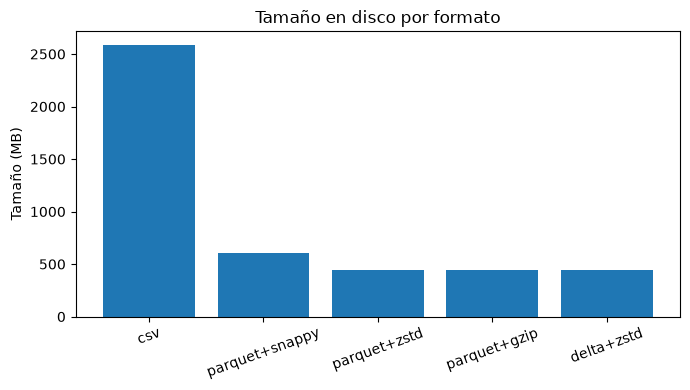

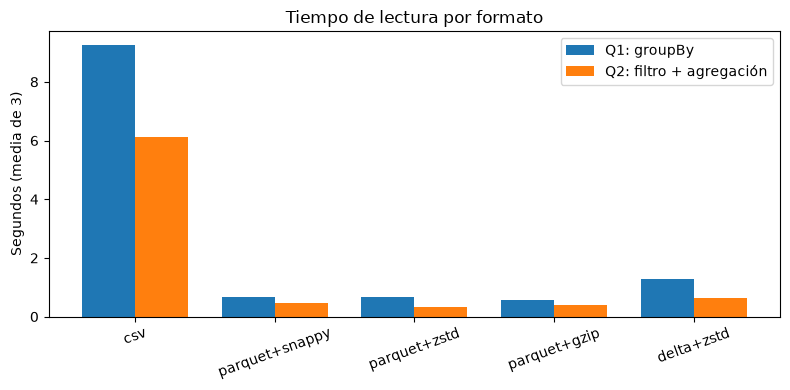

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(t["formato"], t["tamano_mb"])
ax.set_ylabel("Tamaño (MB)"); ax.set_title("Tamaño en disco por formato")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("outputs/bench_tamano.png", dpi=150); plt.show()

x = np.arange(len(t)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, t["lectura_q1_s"], w, label="Q1: groupBy")
ax.bar(x + w/2, t["lectura_q2_s"], w, label="Q2: filtro + agregación")
ax.set_xticks(x); ax.set_xticklabels(t["formato"], rotation=20)
ax.set_ylabel("Segundos (media de 3)"); ax.set_title("Tiempo de lectura por formato")
ax.legend(); plt.tight_layout()
plt.savefig("outputs/bench_lectura.png", dpi=150); plt.show()

In [8]:
for _, r in t.iterrows():
    gb = r["tamano_mb"] * 10 / 1024
    ahorro = (t.loc[0, "tamano_mb"] - r["tamano_mb"]) * 10 / 1024
    print(f"{r['formato']:16s} {gb:7.1f} GB | ahorro vs CSV: {ahorro:7.1f} GB")

csv                 25.3 GB | ahorro vs CSV:     0.0 GB
parquet+snappy       5.9 GB | ahorro vs CSV:    19.4 GB
parquet+zstd         4.3 GB | ahorro vs CSV:    20.9 GB
parquet+gzip         4.4 GB | ahorro vs CSV:    20.9 GB
delta+zstd           4.3 GB | ahorro vs CSV:    20.9 GB


In [9]:
leer(res[2]["ruta"], "parquet").filter(
    (F.col("State") == "CA") & (F.col("Severity") >= 3)).explain()

== Physical Plan ==
*(1) Filter (((isnotnull(State#15211) AND isnotnull(Severity#15202)) AND (State#15211 = CA)) AND (Severity#15202 >= 3))
+- *(1) ColumnarToRow
   +- FileScan parquet [ID#15200,Source#15201,Severity#15202,Start_Time#15203,End_Time#15204,Start_Lat#15205,Start_Lng#15206,Distance_mi#15207,Street#15208,City#15209,County#15210,State#15211,Zipcode#15212,Timezone#15213,Airport_Code#15214,Weather_Timestamp#15215,Temperature_F#15216,Humidity_pct#15217,Pressure_in#15218,Visibility_mi#15219,Wind_Direction#15220,Wind_Speed_mph#15221,Precipitation_in#15222,Weather_Condition#15223,... 23 more fields] Batched: true, DataFilters: [isnotnull(State#15211), isnotnull(Severity#15202), (State#15211 = CA), (Severity#15202 >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/c:/Users/aleja/Desktop/work/outputs/bench/parquet_zstd], PartitionFilters: [], PushedFilters: [IsNotNull(State), IsNotNull(Severity), EqualTo(State,CA), GreaterThanOrEqual(Severity,3)], ReadSchema: struct

### Decisión de formato

**1. Formato elegido para Silver:** Delta Lake con ZSTD. Parquet+ZSTD y Delta+ZSTD pesan lo mismo (443.1 MB, 5.84x menos que el CSV de 2586.7 MB), pero Delta me dio lo que Parquet no puede: UPDATE y MERGE atómicos, time travel y un historial de 16 versiones. El costo medido es de 120.1 s contra 71.8 s de escritura y 1.29 s contra 0.68 s en la consulta Q1. Elegí ZSTD sobre Snappy porque mide 443.1 MB contra 602.0 MB (26% menos) con una lectura equivalente (Q1: 0.68 s contra 0.66 s).

**2. Ahorro con 10x de crecimiento:** CSV pasaría de 2.5 GB a 25.3 GB, Parquet+ZSTD a 4.3 GB (ahorro de 20.9 GB) y Parquet+Snappy a 5.9 GB. ZSTD ahorra 1.55 GB más que Snappy. En tiempo, si la lectura escala de forma lineal (supuesto), Q1 pasaría de 93 s en CSV a 7 s en Parquet+ZSTD.

**3. Comparación con el Tema 3.4:** [completar con los valores de referencia del Tema 3.4]. Mi speedup de Parquet contra CSV (13.7x a 15.9x en Q1, 15x a 18x en Q2) se explica porque mis consultas leen 2 o 3 de 47 columnas (column pruning), mientras que el CSV debe analizar cada fila completa como texto. La compresión de 5.8x viene de los encodings por columna: diccionario para texto repetido (`State`, `Weather_Condition`), RLE para los booleanos y valores repetidos, y luego el códec.

**4. Overhead de Delta+ZSTD:** misma carga útil (443.1 MB), pero la escritura tardó 67% más (120.1 s contra 71.8 s) por el cálculo de estadísticas por archivo y el commit transaccional al log, y la lectura tardó 0.6 s más porque cada lectura reconstruye el snapshot del log. Vale la pena porque con Parquet puro, corregir las 86 filas con `Distance_mi` mayor a 100 habría exigido reescribir toda la tabla sin posibilidad de auditoría ni de revertir.

In [10]:
q = (leer(res[2]["ruta"], "parquet")
     .filter((F.col("State") == "CA") & (F.col("Severity") >= 3))
     .agg(F.count("*"), F.avg("Temperature_F")))
q.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [Severity#15297, State#15306, Temperature_F#15311]
Batched: true
Location: InMemoryFileIndex [file:/c:/Users/aleja/Desktop/work/outputs/bench/parquet_zstd]
PushedFilters: [IsNotNull(State), IsNotNull(Severity), EqualTo(State,CA), GreaterThanOrEqual(Severity,3)]
ReadSchema: struct<Severity:int,State:string,Temperature_F:double>

(2) Filter
Input [3]: [Severity#15297, State#15306, Temperature_F#15311]
Condition : (((isnotnull(State#15306) AND isnotnull(Severity#15297)) AND (State#15306 = CA)) AND (Severity#15297 >= 3))

(3) Project
Output [1]: [Temperature_F#15311]
Input [3]: [Severity#15297, State#15306, Temperature_F#15311]

(4) HashAggregate
Input [1]: [Temperature_F#15311]
Keys: []
Functions [2]: [partial_count(1), partial_avg(Temperature_F#15311)]
Aggregate At

### Predicate pushdown en mi benchmark
El plan físico de Q2 muestra `PushedFilters: [EqualTo(State,CA), GreaterThanOrEqual(Severity,3)]` y `ReadSchema` con solo 3 de 47 columnas. Parquet guarda mínimo y máximo por bloque de filas (row group), y con esos filtros puede saltarse los bloques que no cumplen sin leerlos. En mi caso el beneficio de saltar bloques es limitado: usé repartition(8), que mezcla las filas, así que casi cada bloque contiene registros de muchos estados. No medí cuántos bloques se saltaron. La mejora de Q2 (0.34 s en Parquet+ZSTD contra 6.11 s en CSV) viene sobre todo de leer 3 columnas en lugar de las 47. Si la tabla se hubiera ordenado o particionado por State, el pushdown saltaría muchos más bloques.

In [11]:
shutil.rmtree("outputs/bench", ignore_errors=True)
print(sorted(os.listdir("outputs")))

['bench_lectura.png', 'bench_tamano.png', 'benchmark_resultados.csv', 'calidad_reporte_delta', 'gold', 'gold_delta', 'grafico_estados.png', 'grafico_horas.png', 'silver', 'silver_delta']
